# **MULTILINEAR TENSOR REGRESSION FOR LONGITUDINAL RELATIONAL DATA** (Peter Hoff, 2015)

Following the article, consider a tensor-valued response
$$Y \in \mathbb{R}^{m_1 \times \cdots \times m_K \times n}$$
and a tensor-valued predictor
$$X \in \mathbb{R}^{p_1 \times \cdots \times p_K \times n},$$
where the last dimension represents the longitudinal or temporal dimension.
The multilinear tensor regression model is
$$Y = X \times \{B_1,\ldots,B_K\} + \tau E,$$

where
$$B_k \in \mathbb{R}^{m_k \times p_k}, \qquad k=1,\ldots,K, $$
and
$$E \sim \mathcal{N}_{m_1\times\cdots\times m_K} \left(0,\Sigma_1,\ldots,\Sigma_K \right).$$
The error tensor has separable covariance structure,
$$\operatorname{Cov}\{\operatorname{vec}(E)\} = \Sigma_K\otimes\cdots\otimes\Sigma_1,$$
where
$$\Sigma_k \in \mathbb{S}_{++}^{m_k}.$$
The parameter $\tau^2$ is a global scale parameter that separates the overall error variance from the scale of the mode-specific covariance matrices and regression coefficients.


**Conditional Matrix Regression**

For a given mode $k$, condition on all parameters associated with the other modes,
$$B_{-k}=\{B_j:j\neq k\}, \qquad \Sigma_{-k}=\{\Sigma_j:j\neq k\}.$$
After matricizing the tensors along mode $k$, the model can be written as
$$Y_{(k)} = B_k X_{(k)}B_{-k}^{T} + E_{(k)}.$$
By transforming the other modes with their inverse covariance square roots, define
$$\widetilde{Y}_k = \frac{ Y_{(k)}\Sigma_{-k}^{-1/2}}{\tau},$$
and
$$\widetilde{X}_k = \frac{X_{(k)}B_{-k}^{T}\Sigma_{-k}^{-1/2}}{\tau}.$$
The conditional model becomes the ordinary matrix regression
$$\widetilde{Y}_k = B_k\widetilde{X}_k + \widetilde{E}_k, $$
with
$$\widetilde{E}_k \sim \mathcal{N}_{m_k\times n_k} (0,\Sigma_k,I).$$
Thus, conditional on the remaining modes, estimation of
$(B_k,\Sigma_k)$ reduces to Bayesian multivariate matrix regression.

**Bayesian Model**
For the conditional matrix regression
$$Y \sim \mathcal{N}_{m\times n}(BX,\Sigma,I_n), $$
use the conjugate prior
$$\Sigma \sim \operatorname{Inverse-Wishart} (S_0^{-1},\nu_0), $$
and
$$B\mid\Sigma \sim \mathcal{N}_{m\times p} (M_0,\Sigma,I_p).$$
The posterior distributions are
$$\Sigma\mid Y,X \sim \operatorname{Inverse-Wishart} (S_n^{-1},\nu_0+n),$$
where
$$S_n = S_0 + Y (I_n+X^TX)^{-1} Y^T,$$
and
$$B\mid\Sigma,Y,X\sim \mathcal{N}_{m\times p} (M_n,\Sigma,V_n), $$
where
$$ V_n = (I_p+XX^T)^{-1},$$
and
$$ M_n = (M_0+YX^T)(I_p+XX^T)^{-1}.$$


**ALS Estimation**

Before Bayesian estimation, the coefficient matrices can be initialized using Alternating Least Squares (ALS).
The objective is to find coefficient matrices
$$\widehat{B}_1,\ldots,\widehat{B}_K$$
that minimize the residual sum of squares
$$\operatorname{RSS}(B_1,\ldots,B_K) = \left\|Y-X\times\{B_1,\ldots,B_K\}\right\|_F^2.$$
Because the optimization is multilinear and generally non-convex jointly in all coefficient matrices, ALS estimates each mode-specific coefficient matrix conditionally on the others.
For mode $k$, define
$$Y_{(k)} = B_k X_k + E_{(k)},$$
where $X_k$ is obtained by transforming the predictor tensor using all coefficient matrices except $B_k$.
The least-squares update is
$$\widehat{B}_k = Y_{(k)}X_k^T (X_kX_k^T)^{-1}. $$
The matrices are updated sequentially,
$$ B_1 \rightarrow B_2 \rightarrow \cdots \rightarrow B_K,$$
and the procedure is repeated until convergence or until a maximum number of iterations is reached.
The resulting ALS estimates provide convenient starting values for the Bayesian MCMC algorithm.


**Gibbs Sampling**

The Bayesian model is estimated using a Gibbs sampler whose stationary distribution is the posterior distribution

$$p(B_1,\ldots,B_K, \Sigma_1,\ldots,\Sigma_K,\tau^2\mid Y,X).$$

At each iteration, the sampler updates the parameters conditionally on the current values of all other parameters.

For each mode $k=1,\ldots,K$:

1. Compute the transformed response

$$
\widetilde{Y}_k
=
\frac{
Y_{(k)}\Sigma_{-k}^{-1/2}
}{\tau}.
$$

2. Compute the transformed predictor

$$
\widetilde{X}_k
=
\frac{
X_{(k)}B_{-k}^{T}\Sigma_{-k}^{-1/2}
}{\tau}.
$$

3. Sample the mode-specific covariance matrix from

$$
\Sigma_k
\mid
B_{-k},\Sigma_{-k},\tau^2,Y,X
\sim
\operatorname{Inverse-Wishart}
\left(
S_{nk}^{-1},
\nu_{0k}+n_k
\right),
$$

where

$$
S_{nk}
=
S_{0k}
+
\widetilde{Y}_k
(I+\widetilde{X}_k^T\widetilde{X}_k)^{-1}
\widetilde{Y}_k^T.
$$

4. Conditional on the newly sampled $\Sigma_k$, sample

$$
B_k
\mid
\Sigma_k,\text{rest}
\sim
\mathcal{N}_{m_k\times p_k}
(M_{nk},\Sigma_k,V_{nk}),
$$

where

$$
V_{nk}
=
(I+\widetilde{X}_k\widetilde{X}_k^T)^{-1},
$$

and

$$
M_{nk}
=
(M_{0k}
+
\widetilde{Y}_k\widetilde{X}_k^T)
V_{nk}.
$$



**Update of the Global Variance**

After updating all mode-specific parameters, the global variance parameter is sampled from

$$
\tau^2
\mid
B_1,\ldots,B_K,
\Sigma_1,\ldots,\Sigma_K,
Y,X
\sim
\operatorname{Inverse-Gamma}
\left(
\frac{\eta_0+m}{2},
\frac{
\eta_0\tau_0^2
+
\left\|
Y-
X\times
\{\Sigma_1^{-1/2}B_1,\ldots,
\Sigma_K^{-1/2}B_K\}
\right\|_F^2
}{2}
\right),
$$

where $m=\prod_{k=1}^K m_k$ is the total number of elements in the response tensor.


**Complete Gibbs Algorithm**

The complete Gibbs sampler can therefore be summarized as follows:



1. Initialize
$$
B_1,\ldots,B_K,\quad
\Sigma_1,\ldots,\Sigma_K,\quad
\tau^2.
$$

ALS estimates can be used to initialize the coefficient matrices.

2. For each MCMC iteration:


- For $k=1,\ldots,K$, condition on all other modes and construct
$\widetilde{Y}_k$ and $\widetilde{X}_k$.

- Sample
$$
\Sigma_k
\mid
\text{rest}
$$
from its inverse-Wishart full conditional distribution.

- Sample
$$
B_k
\mid
\Sigma_k,\text{rest}
$$
from its matrix-normal full conditional distribution.

- Sample
$$
\tau^2
\mid
B_1,\ldots,B_K,\Sigma_1,\ldots,\Sigma_K,Y,X
$$
from its inverse-gamma full conditional distribution.


3. If missing observations are present, sample the missing elements of $Y$ from their conditional Gaussian distribution.

4. Store the resulting parameter values after the burn-in period.




**Posterior Inference**

After discarding the burn-in iterations, the MCMC samples

$$
\left\{
B_1^{(s)},\ldots,B_K^{(s)},
\Sigma_1^{(s)},\ldots,\Sigma_K^{(s)},
\tau^{2(s)}
\right\}_{s=1}^{N}
$$

can be used to approximate posterior quantities.

For example, the posterior mean of $B_k$ is estimated by

$$
\widehat{B}_k^{\,\mathrm{post}}
=
\frac{1}{N}
\sum_{s=1}^{N}
B_k^{(s)}.
$$

Posterior uncertainty can be quantified through credible intervals, posterior variances, or probabilities such as

$$
P(B_{k,ij}>0\mid Y,X).
$$

Thus, unlike ALS, which produces a point estimate by minimizing the residual sum of squares, the Bayesian procedure produces an empirical approximation to the full posterior distribution of the model parameters.

## Data

Load data

In [1]:

import numpy as np
import json

X_flat = np.load("data/X.npy")
X = X_flat.reshape((25, 25, 4, 3, 2, 543),order="F")
X_1w = np.load("data/X_1w.npy")
X_1m = np.load("data/X_1m.npy")
Y_flat = np.load("data/Y.npy")
Y = Y_flat.reshape((25, 25, 4, 543), order="F")


print("X:", X.shape)
print("X_1w:", X_1w.shape)
print("X_1m:", X_1m.shape)
print("Y   :", Y.shape)

assert X_1w.shape == (25, 25, 12, 543)
assert X_1m.shape == (25, 25, 12, 543)
assert Y.shape == (25, 25, 4, 543)



with open("data/dimnames_X.json", "r") as f:
    dimnames_X = json.load(f)

with open("data/dimnames_X_1w.json", "r") as f:
    dimnames_X_1w = json.load(f)

with open("data/dimnames_X_1m.json", "r") as f:
    dimnames_X_1m = json.load(f)

with open("data/dimnames_Y.json", "r") as f:
    dimnames_Y = json.load(f)

print("\nDimensions X:")

for k, names in enumerate(dimnames_X):
    print(
        f"Mode {k}: "
        f"{len(names)} elements -> "
        f"{names[:5]}"
    )



print("\nDimensions X_1w:")

for k, names in enumerate(dimnames_X_1w):
    print(
        f"Mode {k}: "
        f"{len(names)} elements -> "
        f"{names[:5]}"
    )


print("\nDimensions X_1m:")

for k, names in enumerate(dimnames_X_1m):
    print(
        f"Mode {k}: "
        f"{len(names)} elements -> "
        f"{names[:5]}"
    )


print("\nDimensions Y:")

for k, names in enumerate(dimnames_Y):
    print(
        f"Mode {k}: "
        f"{len(names)} elements -> "
        f"{names[:5]}"
    )


X: (25, 25, 4, 3, 2, 543)
X_1w: (25, 25, 12, 543)
X_1m: (25, 25, 12, 543)
Y   : (25, 25, 4, 543)

Dimensions X:
Mode 0: 25 elements -> ['AFG', 'AUS', 'CHN', 'DEU', 'EGY']
Mode 1: 25 elements -> ['AFG', 'AUS', 'CHN', 'DEU', 'EGY']
Mode 2: 4 elements -> ['mn', 'mp', 'vn', 'vp']
Mode 3: 3 elements -> ['ij', 'ji', 'ijk']
Mode 4: 2 elements -> ['1w', '1m']
Mode 5: 543 elements -> ['20040205', '20040212', '20040219', '20040226', '20040304']

Dimensions X_1w:
Mode 0: 25 elements -> ['AFG', 'AUS', 'CHN', 'DEU', 'EGY']
Mode 1: 25 elements -> ['AFG', 'AUS', 'CHN', 'DEU', 'EGY']
Mode 2: 12 elements -> ['mn-ij', 'mn-ji', 'mn-ijk', 'mp-ij', 'mp-ji']
Mode 3: 543 elements -> ['20040205', '20040212', '20040219', '20040226', '20040304']

Dimensions X_1m:
Mode 0: 25 elements -> ['AFG', 'AUS', 'CHN', 'DEU', 'EGY']
Mode 1: 25 elements -> ['AFG', 'AUS', 'CHN', 'DEU', 'EGY']
Mode 2: 12 elements -> ['mn-ij', 'mn-ji', 'mn-ijk', 'mp-ij', 'mp-ji']
Mode 3: 543 elements -> ['20040205', '20040212', '20040219', '20

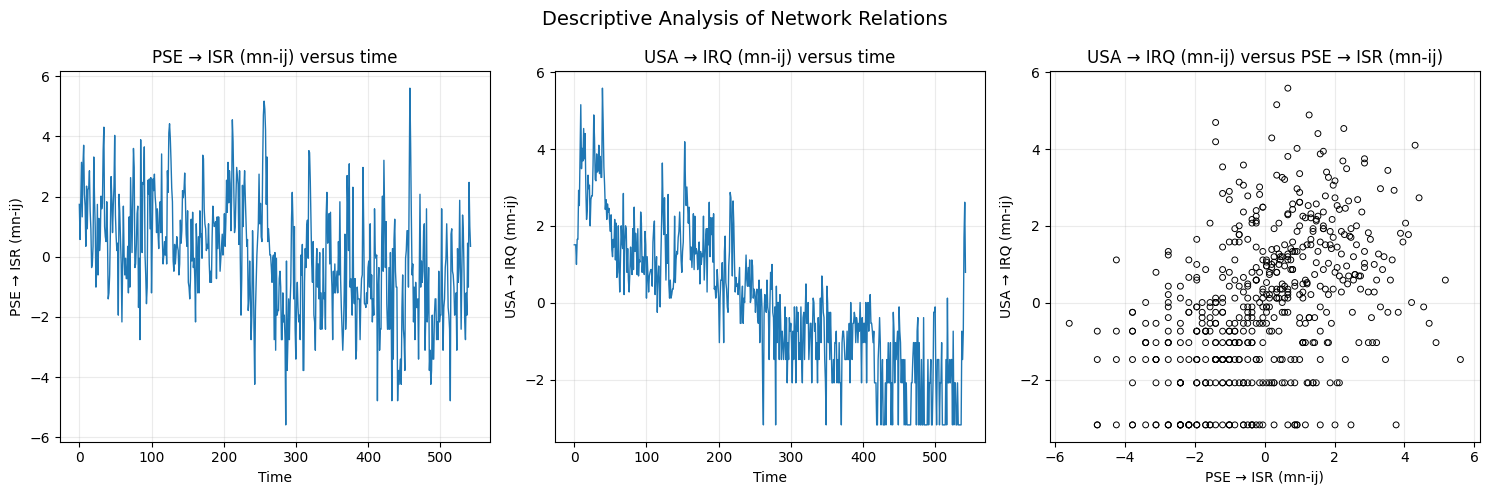

In [72]:


import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# ============================================================
# DESCRIPTIVE FIGURE
# Hoff-style:
#
#   Left:  variable 1 vs. time
#   Middle: variable 2 vs. time
#   Right: variable 1 vs. variable 2
#
# This reproduces the structure of Hoff's Figure 1.
# ============================================================


# ============================================================
# 1. Load dimension names
# ============================================================

with open("data/dimnames_X_1w.json", "r") as f:
    dimnames_X_1w = json.load(f)

countries = dimnames_X_1w[0]

relations = dimnames_X_1w[2]


# ============================================================
# 2. Define the two network relations to visualize
# ============================================================
#
# Y is assumed to have shape:
#
#     (response country,
#      predictor country,
#      relation,
#      time)
#
# Example:
#
#     Y.shape = (25, 25, 4, 543)
#
# Change these values according to the two dyads/relations
# that you want to reproduce from the descriptive analysis.
# ============================================================

# First variable
country_i_1 = 17
country_j_1 = 11
relation_1 = 0

# Second variable
country_i_2 = 24
country_j_2 = 10   
relation_2 = 0


# ============================================================
# 3. Time variable
# ============================================================
#
# Replace this section with your actual dates if available.
#
# If your data contain 543 equally spaced observations, this
# creates a simple integer time index.
# ============================================================

n_time = Y.shape[-1]

time = np.arange(n_time)


# ------------------------------------------------------------
# If you have actual dates, use for example:
#
# time = pd.to_datetime(dates)
# ------------------------------------------------------------


# ============================================================
# 4. Extract the two observed network series
# ============================================================

y1 = Y[
    country_i_1,
    country_j_1,
    relation_1,
    :
]

y2 = Y[
    country_i_2,
    country_j_2,
    relation_2,
    :
]


# ============================================================
# 5. Remove missing observations for the scatterplot
# ============================================================

valid = (
    np.isfinite(y1)
    &
    np.isfinite(y2)
)

y1_scatter = y1[valid]
y2_scatter = y2[valid]


# ============================================================
# 6. Obtain meaningful labels
# ============================================================

country_1_i = countries[country_i_1]
country_1_j = countries[country_j_1]

country_2_i = countries[country_i_2]
country_2_j = countries[country_j_2]

relation_name_1 = relations[relation_1]
relation_name_2 = relations[relation_2]


label_1 = (
    f"{country_1_i} → {country_1_j} "
    f"({relation_name_1})"
)

label_2 = (
    f"{country_2_i} → {country_2_j} "
    f"({relation_name_2})"
)


# ============================================================
# 7. Create Hoff-style figure
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)


# ============================================================
# Panel 1: First relation versus time
# ============================================================

axes[0].plot(
    time,
    y1,
    linewidth=1
)

axes[0].set_xlabel("Time")
axes[0].set_ylabel(label_1)

axes[0].set_title(
    f"{label_1} versus time"
)

axes[0].grid(
    alpha=0.25
)


# ============================================================
# Panel 2: Second relation versus time
# ============================================================

axes[1].plot(
    time,
    y2,
    linewidth=1
)

axes[1].set_xlabel("Time")
axes[1].set_ylabel(label_2)

axes[1].set_title(
    f"{label_2} versus time"
)

axes[1].grid(
    alpha=0.25
)


# ============================================================
# Panel 3: Scatterplot
# ============================================================

axes[2].scatter(
    y1_scatter,
    y2_scatter,
    s=18,
    facecolors="none",
    edgecolors="black",
    linewidths=0.7
)

axes[2].set_xlabel(label_1)
axes[2].set_ylabel(label_2)

axes[2].set_title(
    f"{label_2} versus {label_1}"
)

axes[2].grid(
    alpha=0.25
)


# ============================================================
# 8. Global formatting
# ============================================================

fig.suptitle(
    "Descriptive Analysis of Network Relations",
    fontsize=14
)

fig.tight_layout()

plt.show()

## Auxiliary functions for tensor operations

In [2]:

import numpy as np


# ============================================================
# 1. MATRICIZATION
# ============================================================

def mat(A, k):
    """
    Matricización de un tensor a lo largo del modo k.

    Equivalente a la función mat() de tfunctions.r de Peter Hoff.

    Parameters
    ----------
    A : np.ndarray
        Tensor de dimensión (d1, d2, ..., dK).
    k : int
        Modo a matricizar. Python usa índices 0-based.

    Returns
    -------
    A_k : np.ndarray
        Matriz con:
            filas    = dimensión del modo k
            columnas = producto de las demás dimensiones.

    Example
    -------
    A.shape = (3, 4, 5)

    mat(A, 0).shape = (3, 20)
    mat(A, 1).shape = (4, 15)
    mat(A, 2).shape = (5, 12)
    """

    if not isinstance(A, np.ndarray):
        A = np.asarray(A)

    K = A.ndim

    if k < 0 or k >= K:
        raise ValueError(
            f"El modo k={k} no existe para un tensor "
            f"con {K} dimensiones."
        )

    # Movemos el modo k al frente.
    A_perm = np.moveaxis(A, k, 0)

    # Primera dimensión = modo k.
    # Las demás dimensiones se convierten en columnas.
    A_k = A_perm.reshape(
        A.shape[k],
        -1,
        order="F"
    )

    return A_k


# ============================================================
# 2. ARRAY-MATRIX PRODUCT
# ============================================================

def amprod(A, M, k):
    """
    Producto de un tensor A por una matriz M a lo largo
    del modo k.

    Equivalente a amprod() de tfunctions.r.

    Matemáticamente:

        A ×_k M

    donde:

        A.shape[k] = M.shape[1]

    y el resultado tiene:

        result.shape[k] = M.shape[0]

    Parameters
    ----------
    A : np.ndarray
        Tensor de entrada.

    M : np.ndarray
        Matriz que multiplica el modo k.

    k : int
        Modo sobre el cual se realiza la multiplicación.
        Python usa índices 0-based.

    Returns
    -------
    result : np.ndarray
        Tensor transformado.

    Example
    -------
    A.shape = (5, 4, 3)
    M.shape = (2, 5)

    amprod(A, M, 0).shape = (2, 4, 3)
    """

    A = np.asarray(A)
    M = np.asarray(M)

    if A.ndim == 0:
        raise ValueError("A debe ser un tensor.")

    if M.ndim != 2:
        raise ValueError("M debe ser una matriz 2D.")

    if k < 0 or k >= A.ndim:
        raise ValueError(
            f"El modo k={k} no existe para A.ndim={A.ndim}."
        )

    if M.shape[1] != A.shape[k]:
        raise ValueError(
            f"Dimensiones incompatibles: "
            f"M tiene {M.shape[1]} columnas, "
            f"pero A tiene dimensión {A.shape[k]} "
            f"en el modo {k}."
        )

    # Matricización de A en el modo k
    A_k = mat(A, k)

    # Multiplicación matricial
    # M:    (new_dim, old_dim)
    # A_k:  (old_dim, resto)
    #
    # MA:   (new_dim, resto)
    MA = M @ A_k

    # Nuevas dimensiones:
    # sustituimos solamente la dimensión k
    new_shape = list(A.shape)
    new_shape[k] = M.shape[0]

    # Primero reconstruimos colocando el modo k al frente.
    MA_front = MA.reshape(
        [M.shape[0]] + list(A.shape[:k]) + list(A.shape[k + 1:]),
        order="F"
    )

    # Actualmente:
    #
    # (new_dim, dimensiones antes de k, dimensiones después de k)
    #
    # Queremos:
    #
    # (dimensiones antes de k, new_dim, dimensiones después de k)
    #
    # Para eso movemos el eje 0 nuevamente a la posición k.
    result = np.moveaxis(MA_front, 0, k)

    return result


# ============================================================
# 3. TUCKER PRODUCT
# ============================================================

def tprod(A, B, modes=None):
    """
    Tucker product de un tensor A por una lista de matrices B.

    Equivalente a tprod() de tfunctions.r de Peter Hoff.

    Si:

        B = [B1, B2, ..., BK]

    entonces:

        tprod(A, B)
        =
        A ×_1 B1 ×_2 B2 ... ×_K BK

    Parameters
    ----------
    A : np.ndarray
        Tensor de entrada.

    B : list[np.ndarray]
        Lista de matrices.

    modes : iterable of int, optional
        Modos sobre los cuales realizar la multiplicación.
        Si es None, se utilizan todos los modos correspondientes
        a B.

    Returns
    -------
    X : np.ndarray
        Tucker product.

    Example
    -------
    A.shape = (5, 4, 3)

    B[0].shape = (2, 5)
    B[1].shape = (6, 4)
    B[2].shape = (7, 3)

    tprod(A, B).shape = (2, 6, 7)
    """

    if not isinstance(B, (list, tuple)):
        raise TypeError("B debe ser una lista o tupla de matrices.")

    if modes is None:
        modes = range(len(B))
    else:
        modes = list(modes)

    X = np.asarray(A)

    for k in modes:

        if k < 0 or k >= X.ndim:
            raise ValueError(
                f"El modo {k} no existe para un tensor "
                f"con {X.ndim} dimensiones."
            )

        X = amprod(X, B[k], k)

    return X


# ============================================================
# 4. FUNCIONES AUXILIARES
# ============================================================

def tensor_shape_info(X, name="X"):
    """
    Imprime información básica sobre las dimensiones del tensor.
    """

    print(f"{name}.shape = {X.shape}")
    print(f"{name}.ndim  = {X.ndim}")

    for k, dim in enumerate(X.shape):
        print(f"  modo {k}: {dim}")


def check_tprod_dimensions(X, B, modes=None):
    """
    Comprueba que las dimensiones de las matrices B sean
    compatibles con X para un Tucker product.

    No realiza el producto.
    """

    if modes is None:
        modes = range(len(B))

    for k in modes:

        if k >= X.ndim:
            raise ValueError(
                f"El modo {k} no existe en X."
            )

        expected = X.shape[k]
        actual = B[k].shape[1]

        if expected != actual:
            raise ValueError(
                f"B[{k}] incompatible: "
                f"X.shape[{k}] = {expected}, "
                f"pero B[{k}].shape[1] = {actual}."
            )

    return True

Validation of tensor operations

In [3]:



np.set_printoptions(precision=4,suppress=True)
rng = np.random.default_rng(12345)



def check(condition, message):
    if condition:
        print(f"PASS: {message}")
    else:
        print(f"FAIL: {message}")
        raise AssertionError(message)



print("\n")
print("=" * 70)
print("1. MATRICIZATION TEST")
print("=" * 70)



A = np.arange(1, 25).reshape(
    (2, 3, 4),
    order="F"
)

print("\nTensor A:")
print("shape:", A.shape)
print(A)


# ------------------------------------------------------------
# Matricización modo 0
# ------------------------------------------------------------

A0 = mat(A, 0)

print("\nmat(A, 0)")
print("shape:", A0.shape)
print(A0)


# ------------------------------------------------------------
# Matricización modo 1
# ------------------------------------------------------------

A1 = mat(A, 1)

print("\nmat(A, 1)")
print("shape:", A1.shape)
print(A1)


# ------------------------------------------------------------
# Matricización modo 2
# ------------------------------------------------------------

A2 = mat(A, 2)

print("\nmat(A, 2)")
print("shape:", A2.shape)
print(A2)


# Verificar dimensiones

check(
    A0.shape == (2, 12),
    "mat(A, 0) has dimension (2,12)"
)

check(
    A1.shape == (3, 8),
    "mat(A, 1) has dimension (3,8)"
)

check(
    A2.shape == (4, 6),
    "mat(A, 2) has dimension (4,6)"
)



print("\n")
print("=" * 70)
print("2. MATRICIZATION OF X_1w")
print("=" * 70)


X_1w = np.load(
    "data/X_1w.npy"
)

print("\nX_1w:")
tensor_shape_info(
    X_1w,
    "X_1w"
)


# X_1w:
#
# (25, 25, 12, 543)
#
# Para Hoff:
#
# modo 0 = países
# modo 1 = países
# modo 2 = relación × medición
# modo 3 = tiempo


for k in range(X_1w.ndim):

    Xk = mat(X_1w, k)

    expected_shape = (
        X_1w.shape[k],
        X_1w.size // X_1w.shape[k]
    )

    print(
        f"\nmat(X_1w,{k})"
    )

    print(
        "shape:",
        Xk.shape
    )

    print(
        "expected shape:",
        expected_shape
    )

    check(
        Xk.shape == expected_shape,
        f"mat(X_1w,{k}) has correct dimensions"
    )


# ============================================================

print("\n")
print("=" * 70)
print("3. AMPROD TEST")
print("=" * 70)


# Tensor:
#
# A : 2 × 3 × 4
#
# Matriz:
#
# M : 5 × 2
#
# Entonces:
#
# A ×_0 M
#
# debe tener:
#
# 5 × 3 × 4

A = rng.normal(
    size=(2, 3, 4)
)

M = rng.normal(
    size=(5, 2)
)

AM0 = amprod(
    A,
    M,
    0
)

print("\nA.shape =", A.shape)
print("M.shape =", M.shape)
print("amprod(A,M,0).shape =", AM0.shape)


check(
    AM0.shape == (5, 3, 4),
    "amprod in mode 0 produces (5,3,4)"
)


# ------------------------------------------------------------
# Modo 1
# ------------------------------------------------------------

M1 = rng.normal(
    size=(6, 3)
)

AM1 = amprod(
    A,
    M1,
    1
)

print("\nM1.shape =", M1.shape)
print("amprod(A,M1,1).shape =", AM1.shape)

check(
    AM1.shape == (2, 6, 4),
    "amprod in mode 1 produces (2,6,4)"
)


# ------------------------------------------------------------
# Modo 2
# ------------------------------------------------------------

M2 = rng.normal(
    size=(7, 4)
)

AM2 = amprod(
    A,
    M2,
    2
)

print("\nM2.shape =", M2.shape)
print("amprod(A,M2,2).shape =", AM2.shape)

check(
    AM2.shape == (2, 3, 7),
    "amprod in mode 2 produces (2,3,7)"
)


# ============================================================
# 4. COMPROBAR AMPROD CONTRA LA DEFINICIÓN MATRICIAL
# ============================================================

print("\n")
print("=" * 70)
print("4. MATHEMATICAL VALIDATION OF AMPROD")
print("=" * 70)


# Usamos nuevamente:
#
# A : 2 × 3 × 4
# M : 5 × 2
#
# La definición dice:
#
# mat(A ×_0 M, 0)
# =
# M @ mat(A, 0)

A = rng.normal(
    size=(2, 3, 4)
)

M = rng.normal(
    size=(5, 2)
)

AM = amprod(
    A,
    M,
    0
)

left = mat(
    AM,
    0
)

right = M @ mat(
    A,
    0
)


print("\nLHS:")
print(
    "mat(amprod(A,M,0),0).shape =",
    left.shape
)

print("\nRHS:")
print(
    "M @ mat(A,0).shape =",
    right.shape
)


difference = np.max(
    np.abs(left - right)
)

print(
    "\nMMaximum difference:",
    difference
)


check(
    np.allclose(left, right),
    "amprod satisfies the matrix definition"
)


# ============================================================
# 5. PRUEBA DE TUCKER PRODUCT
# ============================================================

print("\n")
print("=" * 70)
print("5. TUCKER PRODUCT TEST")
print("=" * 70)


# Tensor:
#
# A : 2 × 3 × 4
#
# B0 : 5 × 2
# B1 : 6 × 3
# B2 : 7 × 4
#
# Resultado:
#
# 5 × 6 × 7

A = rng.normal(
    size=(2, 3, 4)
)

B = [

    rng.normal(size=(5, 2)),

    rng.normal(size=(6, 3)),

    rng.normal(size=(7, 4))

]


check_tprod_dimensions(
    A,
    B
)

ABC = tprod(
    A,
    B
)

print("\nA.shape =", A.shape)

for k, Bk in enumerate(B):

    print(
        f"B[{k}].shape =",
        Bk.shape
    )

print(
    "tprod(A,B).shape =",
    ABC.shape
)


check(
    ABC.shape == (5, 6, 7),
    "tprod produces the expected dimensions"
)


# ============================================================
# 6. VALIDAR TUCKER PRODUCT PASO A PASO
# ============================================================

print("\n")
print("=" * 70)
print("6. TUCKER PRODUCT: STEP BY STEP")
print("=" * 70)


step1 = amprod(
    A,
    B[0],
    0
)

step2 = amprod(
    step1,
    B[1],
    1
)

step3 = amprod(
    step2,
    B[2],
    2
)


print("\nAfter B0:")
print(step1.shape)

print("\nAfter B1:")
print(step2.shape)

print("\nAfter B2:")
print(step3.shape)


check(
    np.allclose(ABC, step3),
    "tprod coincides with applying amprod sequentially"
)




# ==========================================================

print("\n")
print("=" * 70)
print("8. IDENTITY TEST")
print("=" * 70)


# Si:
#
# B0 = I
# B1 = I
# B2 = I
#
# entonces:
#
# tprod(A,B) = A

I = [

    np.eye(2),

    np.eye(3),

    np.eye(4)

]

A_identity = tprod(
    A,
    I
)

difference_identity = np.max(
    np.abs(A - A_identity)
)

print(
    "\nMaximum difference:",
    difference_identity
)

check(
    np.allclose(A, A_identity),
    "Tucker product with identity matrices returns A"
)


# ============================================================
# 9. PRUEBA CON X_1w
# ============================================================

print("\n")
print("=" * 70)
print("9. TUCKER PRODUCT WITH X_1w")
print("=" * 70)


# X_1w:
#
# (25,25,12,543)
#
# Queremos transformar los primeros tres modos:
#
# B0 : 25 × 25
# B1 : 25 × 25
# B2 :  4 × 12
#
# El tiempo queda intacto:
#
# 543
#
# Por tanto:
#
# tprod(X_1w,B).shape
#
# = (25,25,4,543)

B_real = [

    rng.normal(
        size=(25, 25)
    ),

    rng.normal(
        size=(25, 25)
    ),

    rng.normal(
        size=(4, 12)
    )

]


check_tprod_dimensions(
    X_1w,
    B_real,
    modes=[0, 1, 2]
)


Y_hat_1w = tprod(
    X_1w,
    B_real,
    modes=[0, 1, 2]
)


print("\nX_1w.shape:")
print(X_1w.shape)

print("\nB0.shape:")
print(B_real[0].shape)

print("\nB1.shape:")
print(B_real[1].shape)

print("\nB2.shape:")
print(B_real[2].shape)

print("\nY_hat_1w.shape:")
print(Y_hat_1w.shape)


check(
    Y_hat_1w.shape == (25, 25, 4, 543),
    "tprod(X_1w,B) produces the dimension of Y"
)


# ============================================================
# 10. VERIFICAR QUE EL TIEMPO NO FUE MODIFICADO
# ============================================================

print("\n")
print("=" * 70)
print("10. VERIFICAR MODO TEMPORAL")
print("=" * 70)


print(
    "X_1w.shape[-1] =",
    X_1w.shape[-1]
)

print(
    "Y_hat_1w.shape[-1] =",
    Y_hat_1w.shape[-1]
)


check(
    X_1w.shape[-1] == Y_hat_1w.shape[-1],
    "The temporal mode remains at 543"
)


# ============================================================
# 11. PRUEBA CON X_1m
# ============================================================

print("\n")
print("=" * 70)
print("11. TUCKER PRODUCT WITH X_1m")
print("=" * 70)


X_1m = np.load(
    "data/X_1m.npy"
)


Y_hat_1m = tprod(
    X_1m,
    B_real,
    modes=[0, 1, 2]
)


print(
    "X_1m.shape =",
    X_1m.shape
)

print(
    "Y_hat_1m.shape =",
    Y_hat_1m.shape
)


check(
    Y_hat_1m.shape == (25, 25, 4, 543),
    "tprod(X_1m,B) produces the dimension of Y"
)


# ============================================================
# 12. PRUEBA FINAL: DOS ESCALAS TEMPORALES
# ============================================================

print("\n")
print("=" * 70)
print("12. TWO TEMPORAL SCALES")
print("=" * 70)


# Modelo:
#
# Y_hat =
#
#     tprod(X_1w, B_1w)
#
#     +
#
#     tprod(X_1m, B_1m)
#
#
# Cada término debe tener:
#
# (25,25,4,543)

B_1w = [

    rng.normal(
        size=(25, 25)
    ),

    rng.normal(
        size=(25, 25)
    ),

    rng.normal(
        size=(4, 12)
    )

]

B_1m = [

    rng.normal(
        size=(25, 25)
    ),

    rng.normal(
        size=(25, 25)
    ),

    rng.normal(
        size=(4, 12)
    )

]


Y_1w = tprod(
    X_1w,
    B_1w,
    modes=[0, 1, 2]
)

Y_1m = tprod(
    X_1m,
    B_1m,
    modes=[0, 1, 2]
)


Y_hat = Y_1w + Y_1m


print("\nY_1w.shape =", Y_1w.shape)
print("Y_1m.shape =", Y_1m.shape)
print("Y_hat.shape =", Y_hat.shape)


check(
    Y_1w.shape == (25,25,4,543),
    "Component 1w has the dimension of Y"
)

check(
    Y_1m.shape == (25,25,4,543),
    "Component 1m has the dimension of Y"
)

check(
    Y_hat.shape == (25,25,4,543),
    "The sum of the two components has the dimension of Y"
)






1. MATRICIZATION TEST

Tensor A:
shape: (2, 3, 4)
[[[ 1  7 13 19]
  [ 3  9 15 21]
  [ 5 11 17 23]]

 [[ 2  8 14 20]
  [ 4 10 16 22]
  [ 6 12 18 24]]]

mat(A, 0)
shape: (2, 12)
[[ 1  3  5  7  9 11 13 15 17 19 21 23]
 [ 2  4  6  8 10 12 14 16 18 20 22 24]]

mat(A, 1)
shape: (3, 8)
[[ 1  2  7  8 13 14 19 20]
 [ 3  4  9 10 15 16 21 22]
 [ 5  6 11 12 17 18 23 24]]

mat(A, 2)
shape: (4, 6)
[[ 1  2  3  4  5  6]
 [ 7  8  9 10 11 12]
 [13 14 15 16 17 18]
 [19 20 21 22 23 24]]
PASS: mat(A, 0) has dimension (2,12)
PASS: mat(A, 1) has dimension (3,8)
PASS: mat(A, 2) has dimension (4,6)


2. MATRICIZATION OF X_1w

X_1w:
X_1w.shape = (25, 25, 12, 543)
X_1w.ndim  = 4
  modo 0: 25
  modo 1: 25
  modo 2: 12
  modo 3: 543

mat(X_1w,0)
shape: (25, 162900)
expected shape: (25, 162900)
PASS: mat(X_1w,0) has correct dimensions

mat(X_1w,1)
shape: (25, 162900)
expected shape: (25, 162900)
PASS: mat(X_1w,1) has correct dimensions

mat(X_1w,2)
shape: (12, 339375)
expected shape: (12, 339375)
PASS: mat(X_1w,2

Initialization of B

In [4]:

def initialize_B(m, p):
    """
    Inicialization de las matrices B_k siguiendo
    la lógica de mlm.ALS() de Peter Hoff.

    Parameters
    ----------
    m : tuple o list
        Dimensiones de Y.

        Ejemplo:
        m = (25, 25, 4, 543)

    p : tuple o list
        Dimensiones de X.

        Ejemplo:
        p = (25, 25, 12, 543)

    Returns
    -------
    B0 : list of np.ndarray
        Lista con las matrices iniciales B_k.

    Notes
    -----
    El último modo corresponde al tiempo y no tiene
    una matriz B asociada.

    Por tanto:

        K = len(m) - 1

    y solamente se generan B_0,...,B_{K-1}.
    """

    m = tuple(m)
    p = tuple(p)

    if len(m) != len(p):
        raise ValueError(
            "X e Y deben tener el mismo número de modos."
        )

    # El último modo es el temporal.
    K = len(m) - 1

    B0 = []

    for k in range(K):

        # Inicialización:
        #
        # B_k : m_k × p_k
        #
        # todos los elementos = 1/p_k

        Bk = np.full(
            (m[k], p[k]),
            1.0 / p[k]
        )

        # Si las dimensiones coinciden,
        # Hoff utiliza la identidad.
        if m[k] == p[k]:

            Bk = np.eye(
                m[k]
            )

        B0.append(Bk)

    return B0


m = Y.shape
p = X_1w.shape

B0 = initialize_B(m, p)

print("m =", m)
print("p =", p)

for k, Bk in enumerate(B0):

    print(
        f"B0[{k}].shape = {Bk.shape}"
    )

m = (25, 25, 4, 543)
p = (25, 25, 12, 543)
B0[0].shape = (25, 25)
B0[1].shape = (25, 25)
B0[2].shape = (4, 12)


Mean squared error

In [5]:


def mse(Y, EY):
    """
    Compute the mean squared error between observed and
    expected tensors.

    This reproduces the behavior of:

        mean((Y - EY)^2, na.rm = TRUE)

    in R.

    Parameters
    ----------
    Y : np.ndarray
        Observed response tensor.

    EY : np.ndarray
        Expected/fitted response tensor.

    Returns
    -------
    float
        Mean squared error.
    """

    Y = np.asarray(Y)
    EY = np.asarray(EY)

    if Y.shape != EY.shape:
        raise ValueError(
            f"Y and EY must have the same shape. "
            f"Got Y={Y.shape}, EY={EY.shape}."
        )

    return np.nanmean(
        (Y - EY) ** 2
    )


## ALS

Alternating Least Squares estimation for multilinear tensor regression

In [6]:


from tqdm import tqdm
def mlm_als(Y, X, tol=1e-5, imax=100, verbose=False, seed=None):
    """
    Alternating Least Squares estimation for multilinear
    tensor regression.
    This function is a Python translation of Peter Hoff's
    mlm.ALS() function.
    Model
    -----
        Y ≈ X ×_1 B_1 ×_2 B_2 ... ×_K B_K
    where the last dimension of X and Y is treated as the
    longitudinal/time dimension and is NOT transformed by
    a coefficient matrix.

    Parameters
    ----------
    Y : np.ndarray
        Response tensor.
        Example:
            Y.shape = (25, 25, 4, 543)
    X : np.ndarray
        Predictor tensor.
        Example:
            X.shape = (25, 25, 12, 543)
    tol : float, default=1e-5
        Convergence tolerance.
    imax : int, default=100
        Maximum number of ALS iterations.
    verbose : bool, default=False
        If True, print the MSE and relative improvement
        at every iteration.
    seed : int or None, default=None
        If None, use Hoff's deterministic initialization
        followed by initial least-squares estimates.
        If an integer is provided, initialize B randomly.
    Returns
    -------
    B : list of np.ndarray
        Estimated coefficient matrices.
        For the current problem:
            B[0].shape = (25,25)
            B[1].shape = (25,25)
            B[2].shape = (4,12)
    """
    mse_history = []
    improvement_history = []
    B_history = []
    # Convert inputs to NumPy arrays
    Y = np.asarray(Y, dtype=float)
    X = np.asarray(X, dtype=float)
    # Check that Y and X have the same number of dimensions.
    if Y.ndim != X.ndim:
        raise ValueError("X and Y must have the same number of dimensions.")
    # Check that the last dimension is the same.
    # The last dimension represents time/longitudinal
    # observations and is shared by X and Y.
    if Y.shape[-1] != X.shape[-1]:
        raise ValueError("The last dimension of X and Y must be the same.")
    # Save the original response
    # This corresponds to Y0 <- Y in Hoff's R code.
    # We need Y0 because Y will later be modified at missing
    # positions during the iterative fitting procedure.
    Y0 = Y.copy()
    # Replace missing Y values temporarily
    # Y0 still contains the original missing values.
    # Y is only a working copy used by the ALS algorithm.
    Y_work = Y.copy()
    Y_work[np.isnan(Y_work)] = 0.0
    # Determine tensor dimensions
    m = Y.shape
    p = X.shape
    # The final dimension is time. Therefore the number of coefficient matrices is:
    K = len(m) - 1
    # Initialize B
    if seed is None:
        # Deterministic initialization used by Hoff
        B0 = initialize_B(m, p)
        # Start B as a copy of B0.
        # We use copies because B will be modified.
        B = [Bk.copy() for Bk in B0]
    else:
        # Random initialization.
        rng = np.random.default_rng(seed)
        B = []
        scale = np.prod(p)
        for k in range(K):
            Bk = rng.normal(loc=0.0, scale=1.0, size=(m[k], p[k]))
            Bk = Bk / scale
            B.append(Bk)
    # Initial fitted values
    EY = tprod(X, B, modes=range(K))
    # Impute missing Y values
    missing = np.isnan(Y0)
    Y_work[missing] = EY[missing]
    # Initial MSE
    current_mse = mse(Y0, EY)
    old_mse = np.inf
    # ALS iterations
    i = 0
    # Store
    mse_history.append(current_mse)
    B_history.append([
        Bk.copy()
        for Bk in B
    ])
    
    with tqdm(total=imax, desc="ALS", unit="iter", dynamic_ncols=True, disable=not verbose) as pbar:
        while ((old_mse - current_mse) / current_mse > tol and i < imax):
            old_mse = current_mse
            # Randomize the order of the modes
            if seed is None:
                mode_order = np.random.permutation(K)
            else:
                mode_order = rng.permutation(K)
            # Update each B[k]
            for k in mode_order:
                # Transform X using all B matrices except B[k].
                other_modes = [j for j in range(K) if j != k]
                X_transformed = tprod(X,B,modes=other_modes)
                # Matricize X and Y.
                Xk = mat(X_transformed, k)
                Yk = mat(Y_work, k)
                # Solve: B[k] = Yk Xk'(Xk Xk')^{-1}
                Xt = Xk.T
                XXt = Xk @ Xt
                YXt = Yk @ Xt
                try:
                    B[k] = np.linalg.solve(XXt.T, YXt.T).T
                except np.linalg.LinAlgError:
                    # If Xk Xk' is singular or nearly singular, use the Moore-Penrose pseudoinverse.
                    B[k] = (YXt @ np.linalg.pinv(XXt))
            # Recalculate fitted values
            EY = tprod(X, B, modes=range(K))
            # Update missing observations
            Y_work[missing] = EY[missing]
            # Calculate the new MSE
            current_mse = mse(Y0, EY)
            # Increase iteration counter
            i += 1
            # Print convergence information
            improvement = ((old_mse - current_mse)/current_mse)
            mse_history.append(current_mse)
            improvement_history.append(improvement)
            B_history.append([Bk.copy() for Bk in B])
            pbar.update(1)
            pbar.set_postfix(MSE=f"{current_mse:.4e}", improvement=f"{improvement:.4e}", tol=f"{tol:.1e}")
    # Final information
    if verbose:
        if i >= imax:
            print(f"\nALS stopped because imax={imax} " 
                f"was reached.")
        else:
            print(f"\nALS converged after {i} iterations.")
        print(f"Final MSE = {current_mse:.8e}")
    # Return estimated coefficient matrices

    history = {
        "mse": mse_history,
        "improvement": improvement_history,
        "B": B_history,
        "iterations": i
    }


    return B, history

Test on data

In [7]:
B_1w, history_1w = mlm_als(Y=Y, X=X_1w, tol=1e-12, imax=1000, verbose=True, seed=None)

ALS:   2%|▏         | 19/1000 [00:09<08:15,  1.98iter/s, MSE=9.0522e-01, improvement=6.3322e-13, tol=1.0e-12]


ALS converged after 19 iterations.
Final MSE = 9.05222071e-01


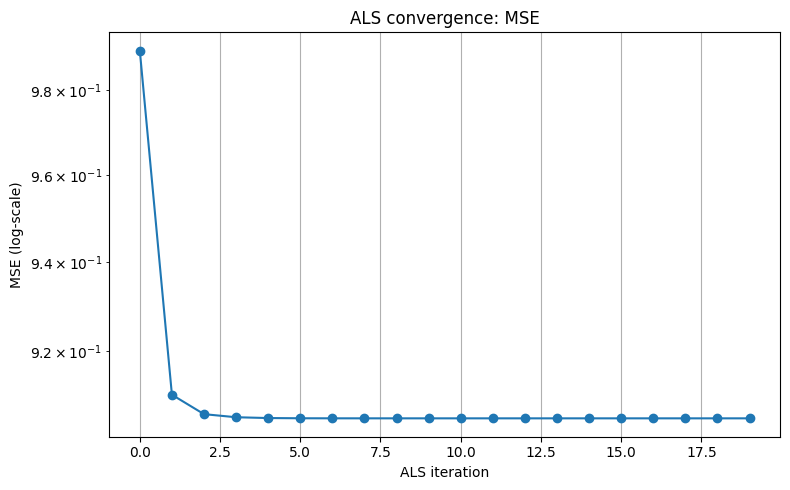

In [8]:

import matplotlib.pyplot as plt


mse_history = history_1w["mse"]

plt.figure(figsize=(8, 5))

plt.plot(
    range(len(mse_history)),
    mse_history,
    marker="o"
)

plt.yscale("log")
plt.xlabel("ALS iteration")
plt.ylabel("MSE (log-scale)")
plt.title("ALS convergence: MSE")

plt.grid(True)
plt.tight_layout()
plt.show()

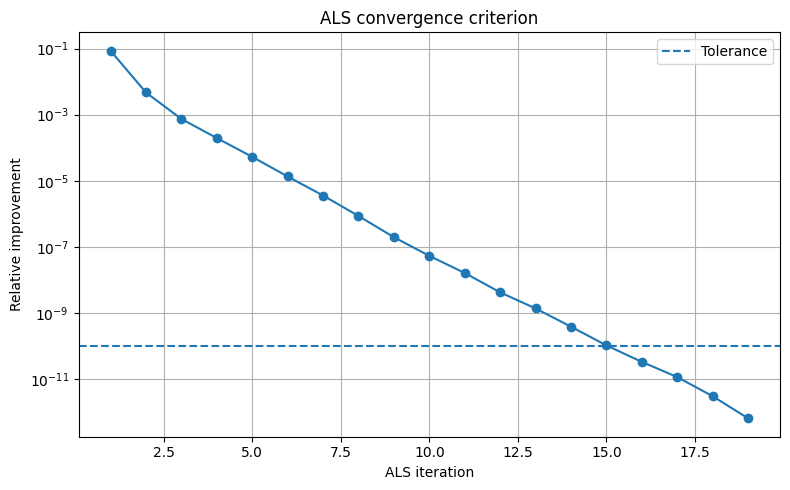

In [9]:

improvement_history = history_1w["improvement"]

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(improvement_history) + 1),
    improvement_history,
    marker="o"
)

plt.yscale("log")

plt.axhline(
    1e-10,
    linestyle="--",
    label="Tolerance"
)

plt.xlabel("ALS iteration")
plt.ylabel("Relative improvement")
plt.title("ALS convergence criterion")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

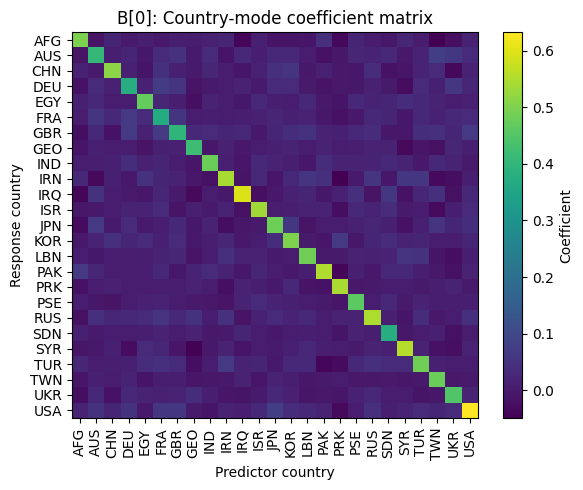

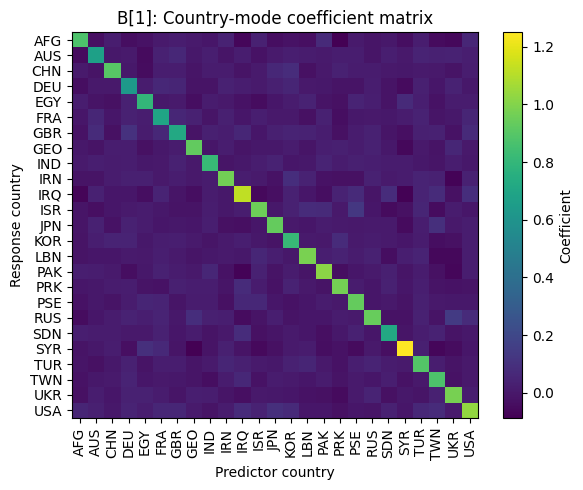

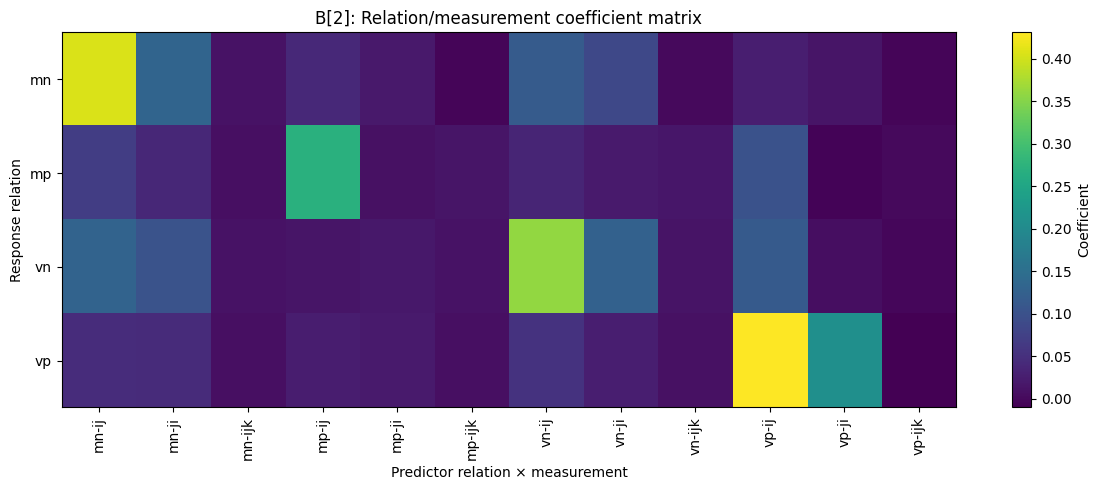

In [10]:

import json

with open("data/dimnames_X_1w.json", "r") as f:
    dimnames_X_1w = json.load(f)

countries = dimnames_X_1w[0]

B0 = B_1w[0]
B1 = B_1w[1]
B2 = B_1w[2]

plt.figure(figsize=(6, 5))

plt.imshow(
    B0,
    aspect="auto"
)

plt.colorbar(
    label="Coefficient"
)

plt.xticks(
    range(len(countries)),
    countries,
    rotation=90
)

plt.yticks(
    range(len(countries)),
    countries
)

plt.xlabel("Predictor country")
plt.ylabel("Response country")

plt.title("B[0]: Country-mode coefficient matrix")

plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))

plt.imshow(
    B1,
    aspect="auto"
)

plt.colorbar(
    label="Coefficient"
)

plt.xticks(
    range(len(countries)),
    countries,
    rotation=90
)

plt.yticks(
    range(len(countries)),
    countries
)

plt.xlabel("Predictor country")
plt.ylabel("Response country")

plt.title("B[1]: Country-mode coefficient matrix")

plt.tight_layout()
plt.show()


relations = dimnames_X_1w[2]
measurements = ["ij", "ji", "ijk"]

response_relations = ["mn", "mp", "vn", "vp"]

predictor_names = [
    "mn-ij", "mn-ji", "mn-ijk",
    "mp-ij", "mp-ji", "mp-ijk",
    "vn-ij", "vn-ji", "vn-ijk",
    "vp-ij", "vp-ji", "vp-ijk"
]
plt.figure(figsize=(12, 5))

plt.imshow(
    B_1w[2],
    aspect="auto"
)

plt.colorbar(
    label="Coefficient"
)

plt.xticks(
    range(12),
    predictor_names,
    rotation=90
)

plt.yticks(
    range(4),
    response_relations
)

plt.xlabel(
    "Predictor relation × measurement"
)

plt.ylabel(
    "Response relation"
)

plt.title(
    "B[2]: Relation/measurement coefficient matrix"
)

plt.tight_layout()
plt.show()

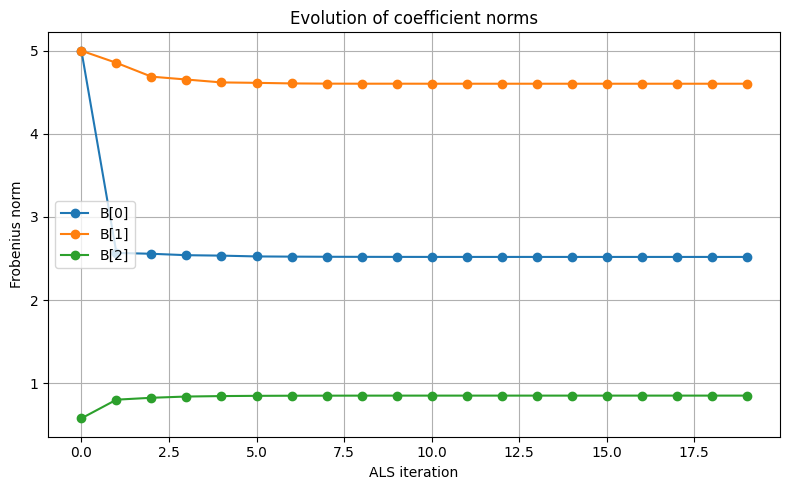

In [11]:

B_history = history_1w["B"]

B_norms = np.array([
    [
        np.linalg.norm(Bk)
        for Bk in B_iter
    ]
    for B_iter in B_history
])

plt.figure(figsize=(8, 5))

for k in range(B_norms.shape[1]):

    plt.plot(
        B_norms[:, k],
        marker="o",
        label=f"B[{k}]"
    )

plt.xlabel("ALS iteration")
plt.ylabel("Frobenius norm")

plt.title("Evolution of coefficient norms")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## MCMC

### Functions

In [12]:
import numpy as np
from scipy.stats import wishart, gamma
from scipy.linalg import sqrtm


def rsan(shape, rng=None):
    """
    Equivalent to Hoff's rsan().
    Generates a matrix/tensor of independent N(0,1) variables.
    """
    if rng is None:
        rng = np.random.default_rng()

    return rng.normal(size=shape)


def mhalf(A):
    """
    Symmetric matrix square root.

    For a positive-definite matrix A, returns A^(1/2).
    """
    A = np.asarray(A, dtype=float)

    # Force numerical symmetry
    A = (A + A.T) / 2

    eigenvalues, eigenvectors = np.linalg.eigh(A)

    # Numerical protection
    eigenvalues = np.maximum(eigenvalues, 0.0)

    return (
        eigenvectors
        @ np.diag(np.sqrt(eigenvalues))
        @ eigenvectors.T
    )


def rwish(scale, df, rng=None):
    """
    Equivalent to the Wishart draw used by Hoff.

    scipy.stats.wishart uses:
        W ~ Wishart(df, scale)

    with:
        E[W] = df * scale
    """
    if rng is None:
        rng = np.random.default_rng()

    return wishart.rvs(
        df=df,
        scale=scale,
        random_state=rng
    )

In [13]:
def rBSm_fc(Y, X, B0=None, rng=None):
    """
    Bayesian matrix regression update.

    Model:
        Y = B @ X + E

    with:
        Y : (m, n)
        X : (p, n)
        B : (m, p)

    Returns
    -------
    B : ndarray
        Posterior draw of B.

    iSh : ndarray
        Square root of the sampled precision matrix.
    """

    if rng is None:
        rng = np.random.default_rng()

    Y = np.asarray(Y, dtype=float)
    X = np.asarray(X, dtype=float)

    # Optional centering by B0
    if B0 is not None:
        B0 = np.asarray(B0, dtype=float)
        Y = Y - B0 @ X

    # Dimensions
    m, n = Y.shape
    p = X.shape[0]

    # (I_p + X X')
    A = np.eye(p) + X @ X.T

    # iIXX = (I_p + X X')^{-1}
    iIXX = np.linalg.solve(A, np.eye(p))

    # Y X'
    YX = Y @ X.T

    # Y Y'
    YY = Y @ Y.T

    # Matrix entering the Wishart distribution
    W = (
        np.eye(m)
        + YY
        - YX @ iIXX @ YX.T
    )

    # Wishart scale matrix
    wishart_scale = np.linalg.solve(W, np.eye(m))

    # Draw precision matrix
    iS = rwish(
        scale=wishart_scale,
        df=m + 1 + n,
        rng=rng
    )

    # Square root of precision
    iSh = mhalf(iS)

    # Posterior mean of B
    M = YX @ iIXX

    # Standard matrix-normal random component
    Z = rsan((m, p), rng=rng)

    # B posterior draw
    B = M + np.linalg.solve(
        iSh,
        Z @ mhalf(iIXX)
    )

    # Add B0 back
    if B0 is not None:
        B = B + B0

    return {
        "B": B,
        "iSh": iSh
    }

In [38]:
from scipy.stats import invgamma


def rBSa_fc(Y, X, B, S, B0=None, rng=None):
    """
    One Gibbs update for Hoff's multilinear tensor regression.

    Parameters
    ----------
    Y : ndarray
        Response tensor.

    X : ndarray
        Predictor tensor.

    B : list of ndarray
        Current coefficient matrices.

    S : list of ndarray
        Current covariance matrices.

    B0 : list of ndarray or None
        Prior/reference matrices.

    rng : np.random.Generator or None

    Returns
    -------
    dict
        Updated B, S and s2.
    """

    if rng is None:
        rng = np.random.default_rng()

    Y = np.asarray(Y, dtype=float)
    X = np.asarray(X, dtype=float)

    K = len(B)

    # --------------------------------------------------
    # Precision square roots:
    # iSh[k] = Sigma_k^(-1/2)
    # --------------------------------------------------

    iSh = []

    for Sk in S:

        precision = np.linalg.solve(
            Sk,
            np.eye(Sk.shape[0])
        )

        iSh.append(mhalf(precision))

    # --------------------------------------------------
    # Update s²
    # --------------------------------------------------

    XB = tprod(X, B)

    R = Y - XB

    R_white = tprod(R, iSh)

    shape = (Y.size + 1) / 2
    scale = (np.sum(R_white ** 2) + 1) / 2

    s2 = invgamma.rvs(
        a=shape,
        scale=scale,
        random_state=rng
    )

    # --------------------------------------------------
    # Update modes in random order
    # --------------------------------------------------

    mode_order = rng.permutation(K)

    for k in mode_order:

        other_modes = [
            j for j in range(K)
            if j != k
        ]

        # ----------------------------------------------
        # Transform Y
        # ----------------------------------------------

        Y_transformed = tprod(
            Y,
            iSh,
            modes=other_modes
        )

        Yk = mat(
            Y_transformed,
            k
        ) / np.sqrt(s2)

        # ----------------------------------------------
        # Transform X
        # ----------------------------------------------

        iShB = [
            iSh[j] @ B[j]
            for j in range(K)
        ]

        X_transformed = tprod(
            X,
            iShB,
            modes=other_modes
        )

        Xk = mat(
            X_transformed,
            k
        ) / np.sqrt(s2)

        # ----------------------------------------------
        # Bayesian matrix regression update
        # ----------------------------------------------

        B0_k = None

        if B0 is not None:
            B0_k = B0[k]

        BS = rBSm_fc(
            Yk,
            Xk,
            B0=B0_k,
            rng=rng
        )

        # Update B_k
        B[k] = BS["B"]

        # Update precision square root
        iSh[k] = BS["iSh"]

    # --------------------------------------------------
    # Recover covariance matrices
    # --------------------------------------------------

    S = []

    for H in iSh:

        H_inv = np.linalg.solve(
            H,
            np.eye(H.shape[0])
        )

        S.append(H_inv @ H_inv)

    return {
        "B": B,
        "S": S,
        "s2": s2
    }

In [39]:
import numpy as np


def B_scaled(B):
    """
    Normalize the scale of the coefficient matrices B.

    The multilinear model is invariant to reciprocal rescaling
    of the coefficient matrices. This function removes that
    scale non-identifiability so that MCMC samples can be
    compared across iterations.
    """

    K = len(B)

    # Compute the root mean square magnitude of each B_k
    MB = np.array([
        np.sqrt(np.mean(Bk**2))
        for Bk in B
    ])

    # Rescaling factors.
    # Their product is 1, so the overall multilinear product
    # remains unchanged.
    sB = np.prod(MB)**(1.0 / K) / MB

    # Apply the scale correction to each coefficient matrix
    BS = [
        B[k] * sB[k]
        for k in range(K)
    ]

    # Resolve sign indeterminacy between consecutive matrices.
    # For square matrices, use the sign of the median diagonal.
    # For rectangular matrices, use the sign of the first element.
    for k in range(K - 1):

        if BS[k].shape[0] == BS[k].shape[1]:
            sk = np.sign(np.median(np.diag(BS[k])))
        else:
            sk = np.sign(BS[k][0, 0])

        # Transfer the sign between consecutive modes.
        BS[k] = BS[k] * sk
        BS[k + 1] = BS[k + 1] * sk

    return BS


def S_scaled(S, s2):
    """
    Normalize the scale of the covariance matrices S and s2.

    This removes the scale non-identifiability between the
    mode-specific covariance matrices and the global variance
    parameter s2.
    """

    K = len(S)

    # Dimension of each covariance matrix S_k
    m = np.array([
        Sk.shape[0]
        for Sk in S
    ], dtype=float)

    # Scaling factor for each covariance matrix:
    # m_k / trace(S_k)
    sS = np.array([
        m[k] / np.trace(S[k])
        for k in range(K)
    ])

    # Compensate s2 for the rescaling applied to all S_k.
    s2s = s2 / np.prod(sS)

    # Apply the scale correction to each covariance matrix
    SS = [
        S[k] * sS[k]
        for k in range(K)
    ]

    return {
        "S": SS,
        "s2": s2s
    }

In [40]:
import numpy as np


def initialize_mcmc(
    Y,
    X,
    rstart=False,
    seed=None,
    als_imax=5
):
    """
    Initialize the MCMC sampler.

    Parameters
    ----------
    Y : ndarray
        Response tensor.

    X : ndarray
        Predictor tensor.

    rstart : bool
        If False, initialize from the ALS estimates.
        If True, initialize randomly.

    seed : int or None
        Random seed.

    als_imax : int
        Number of ALS iterations used for initialization.

    Returns
    -------
    B : list of ndarray
        Initial coefficient matrices.

    BMLE : list of ndarray or None
        ALS estimates.

    S : list of ndarray
        Initial covariance matrices.

    s2 : float
        Initial global variance parameter.

    YI : ndarray
        Response tensor with missing values initially imputed.
    """

    rng = np.random.default_rng(seed)

    # Number of coefficient matrices.
    # The last dimension is the longitudinal/time dimension.
    K = Y.ndim - 1

    # --------------------------------------------------
    # Initialization using ALS
    # --------------------------------------------------

    if not rstart:

        # Obtain initial coefficient estimates using ALS.
        BMLE, _ = mlm_als(
            Y,
            X,
            imax=als_imax,
            verbose=True,
            seed=None
        )

        # Copy the ALS estimates.
        B = [
            Bk.copy()
            for Bk in BMLE
        ]

        # Initial fitted values.
        XB = tprod(X, B, modes=range(K))

        # Impute missing observations using the ALS fit.
        YI = Y.copy()

        missing = np.isnan(Y)

        YI[missing] = XB[missing]

        # Initial residual tensor.
        R = YI - XB

        # Initialize the mode-specific covariance matrices.
        S = []

        for k in range(K):

            # Matricize the residual tensor along mode k.
            Rk = mat(R, k)

            # Compute R_k R_k'.
            Sk = Rk @ Rk.T

            # Normalize S_k so that trace(S_k) = dimension.
            mk = Sk.shape[0]

            Sk = Sk * (mk / np.trace(Sk))

            S.append(Sk)

        # Initial global variance.
        s2 = np.mean(R**2)

    # --------------------------------------------------
    # Random initialization
    # --------------------------------------------------

    else:

        B = []
        S = []

        for k in range(K):

            # Random initial coefficient matrix.
            Bk = rsan(
                (Y.shape[k], X.shape[k]),
                rng=rng
            )

            B.append(Bk)

            # Random initial positive-definite covariance matrix.
            # We sample a Wishart precision matrix and invert it.
            mk = Y.shape[k]

            precision = rwish(
                scale=np.eye(mk),
                df=mk,
                rng=rng
            )

            Sk = np.linalg.solve(
                precision,
                np.eye(mk)
            )

            S.append(Sk)

        # Random initial global variance.
        s2 = rng.gamma(
            shape=1.0,
            scale=1.0
        )

        # Initial fitted values.
        XB = tprod(X, B, modes=range(K))

        # Initialize missing observations.
        YI = Y.copy()

        missing = np.isnan(Y)

        YI[missing] = XB[missing]

        BMLE = None

    return B, BMLE, S, s2, YI

In [41]:
def initialize_mcmc_storage(Y, X):
    """
    Initialize containers for storing MCMC samples.
    """

    K = Y.ndim - 1

    # Store MSE and scaled global variance.
    MSE = []
    S2 = []

    # Store scaled coefficient and covariance samples.
    BPS = []
    SPS = []

    for k in range(K):

        # Shape:
        #   (m_k, p_k, number_of_iterations)
        BPS.append(
            np.empty(
                (
                    Y.shape[k],
                    X.shape[k],
                    0
                )
            )
        )

        # Shape:
        #   (m_k, m_k, number_of_iterations)
        SPS.append(
            np.empty(
                (
                    Y.shape[k],
                    Y.shape[k],
                    0
                )
            )
        )

    return MSE, S2, BPS, SPS

In [42]:
def run_mcmc(
    Y,
    X,
    B,
    S,
    s2,
    YI,
    NS,
    NB,
    B0=None,
    seed=None,
    verbose=True
):
    """
    Run Hoff's Gibbs sampler for multilinear tensor regression.

    Parameters
    ----------
    Y : ndarray
        Original response tensor, possibly containing NaNs.

    X : ndarray
        Predictor tensor.

    B : list of ndarray
        Initial coefficient matrices.

    S : list of ndarray
        Initial covariance matrices.

    s2 : float
        Initial global variance.

    YI : ndarray
        Response tensor with missing values initialized.

    NS : int
        Number of posterior samples after burn-in.

    NB : int
        Number of burn-in iterations.

    B0 : list of ndarray or None
        Prior/reference coefficient matrices.

    seed : int or None
        Random seed.

    verbose : bool
        Print MCMC progress.

    Returns
    -------
    results : dict
        MCMC samples and diagnostics.
    """

    rng = np.random.default_rng(seed)

    K = Y.ndim - 1

    # --------------------------------------------------
    # Output containers
    # --------------------------------------------------

    MSE = []
    S2 = []

    BPS = []
    SPS = []

    for k in range(K):

        BPS.append(
            np.empty(
                (
                    Y.shape[k],
                    X.shape[k],
                    0
                )
            )
        )

        SPS.append(
            np.empty(
                (
                    Y.shape[k],
                    Y.shape[k],
                    0
                )
            )
        )

    # Original missing-data mask.
    missing = np.isnan(Y)

    # --------------------------------------------------
    # MCMC
    # --------------------------------------------------

    total_iterations = NS + NB

    pbar = tqdm(
        range(total_iterations),
        desc="MCMC Gibbs Sampling",
        unit="iter",
        dynamic_ncols=True,
        disable=not verbose
    )

    for s in pbar:

        # --------------------------------------------------
        # Gibbs update
        # --------------------------------------------------

        BS = rBSa_fc(
            YI,
            X,
            B,
            S,
            B0=B0,
            rng=rng
        )

        B = BS["B"]
        S = BS["S"]
        s2 = BS["s2"]

        # --------------------------------------------------
        # Impute missing observations
        # --------------------------------------------------

        # Current fitted mean:
        # E[Y | X, B]
        XB = tprod(
            X,
            B,
            modes=range(K)
        )

        # Generate standard normal tensor.
        Z = rsan(
            Y.shape,
            rng=rng
        )

        # Generate tensor-valued Gaussian error:
        #
        # sqrt(s2) * E
        #
        # where E has separable covariance
        # S_1, ..., S_K.
        error = tprod(
            Z,
            [
                mhalf(Sk)
                for Sk in S
            ],
            modes=range(K)
        )

        # New values are generated only at missing positions.
        YI[missing] = (
            XB + np.sqrt(s2) * error
        )[missing]

        # --------------------------------------------------
        # Scale covariance matrices and s2
        # --------------------------------------------------

        SS2 = S_scaled(
            S,
            s2
        )

        S2.append(
            SS2["s2"]
        )

        # --------------------------------------------------
        # Store scaled B samples
        # --------------------------------------------------

        B_scaled_current = B_scaled(B)

        for k in range(K):

            # Add a new MCMC sample along axis 2.
            BPS[k] = np.concatenate(
                [
                    BPS[k],
                    B_scaled_current[k][:, :, None]
                ],
                axis=2
            )

        # --------------------------------------------------
        # Store scaled covariance samples
        # --------------------------------------------------

        for k in range(K):

            SPS[k] = np.concatenate(
                [
                    SPS[k],
                    SS2["S"][k][:, :, None]
                ],
                axis=2
            )

        # --------------------------------------------------
        # MSE
        # --------------------------------------------------

        current_mse = np.mean(
            (YI - XB) ** 2
        )

        MSE.append(
            current_mse
        )

        # Update progress bar
        pbar.set_postfix(
            MSE=f"{current_mse:.4e}",
            s2=f"{s2:.4e}"
        )

        

    return {
        "B": B,
        "S": S,
        "s2": s2,
        "YI": YI,
        "MSE": np.asarray(MSE),
        "S2": np.asarray(S2),
        "BPS": BPS,
        "SPS": SPS,
        "burn_in": NB,
        "n_samples": NS
    }

### Results

In [73]:
# Initialize
B, BMLE, S, s2, YI = initialize_mcmc(Y=Y, X=X_1w, rstart=False, seed=123, als_imax=10)
# Run Gibbs sampler
results = run_mcmc(Y=Y, X=X_1w, B=B, S=S, s2=s2, YI=YI, NS=1000, NB=500, seed=123, verbose=True)
# Extract posterior samples
BPS = results["BPS"]
SPS = results["SPS"]
MSE = results["MSE"]
S2 = results["S2"]

ALS:  70%|███████   | 7/10 [00:02<00:01,  2.68iter/s, MSE=9.0522e-01, improvement=5.3882e-06, tol=1.0e-05]



ALS converged after 7 iterations.
Final MSE = 9.05223848e-01


MCMC Gibbs Sampling: 100%|██████████| 1500/1500 [22:33<00:00,  1.11iter/s, MSE=9.1602e-01, s2=1.7626e+00]


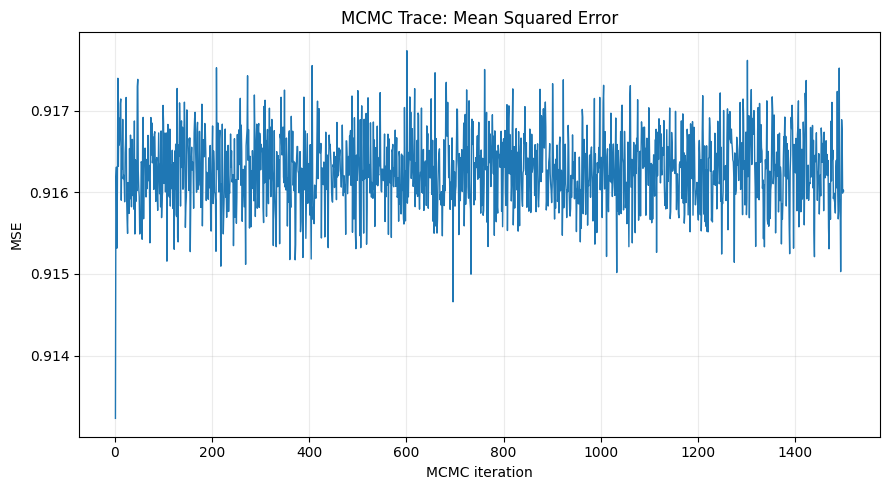

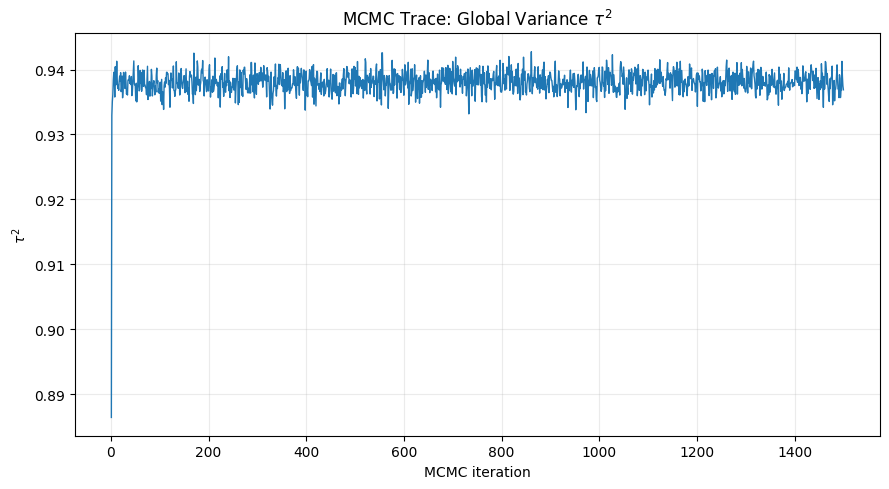

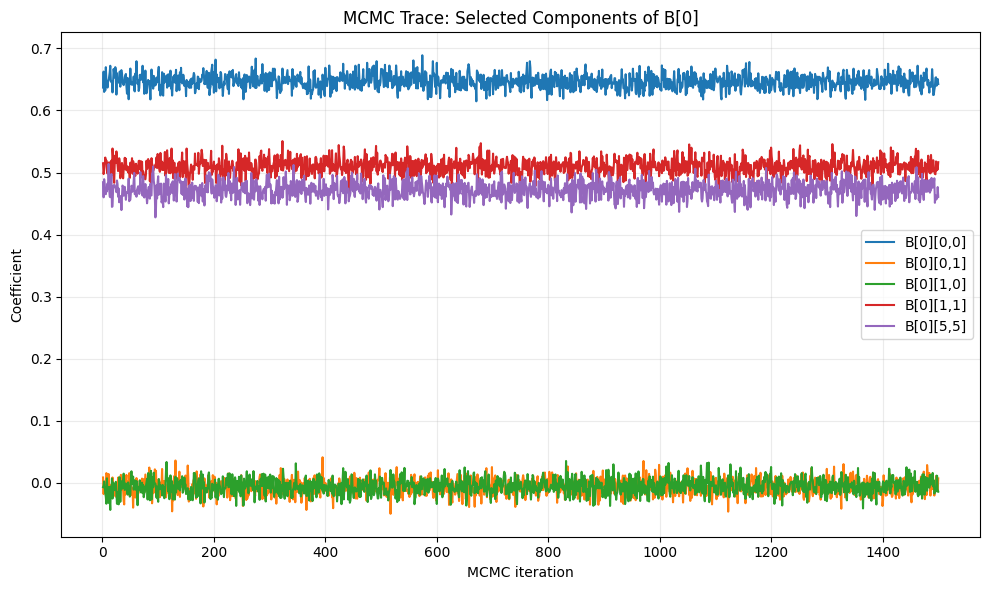

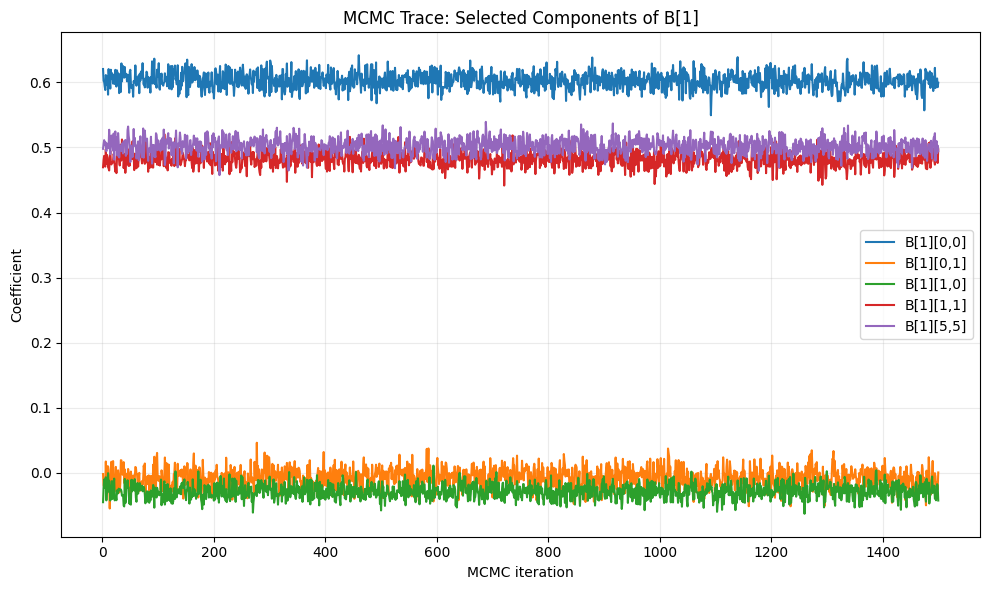

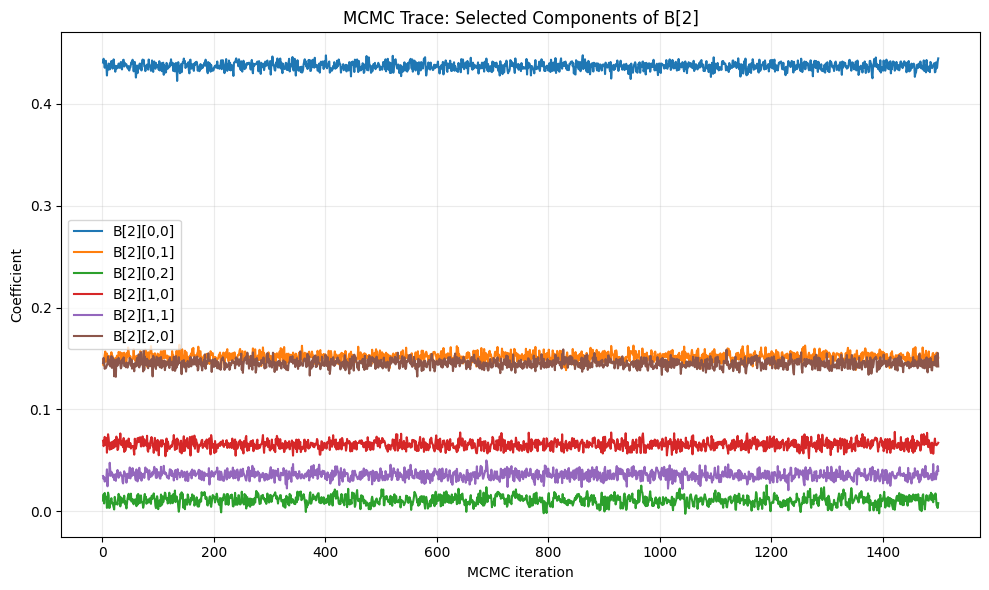

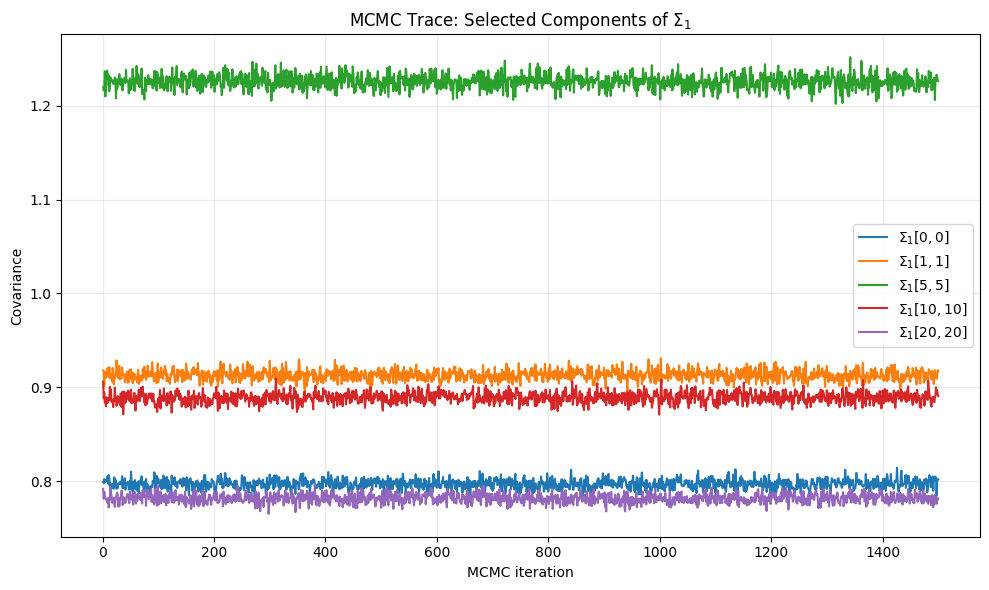

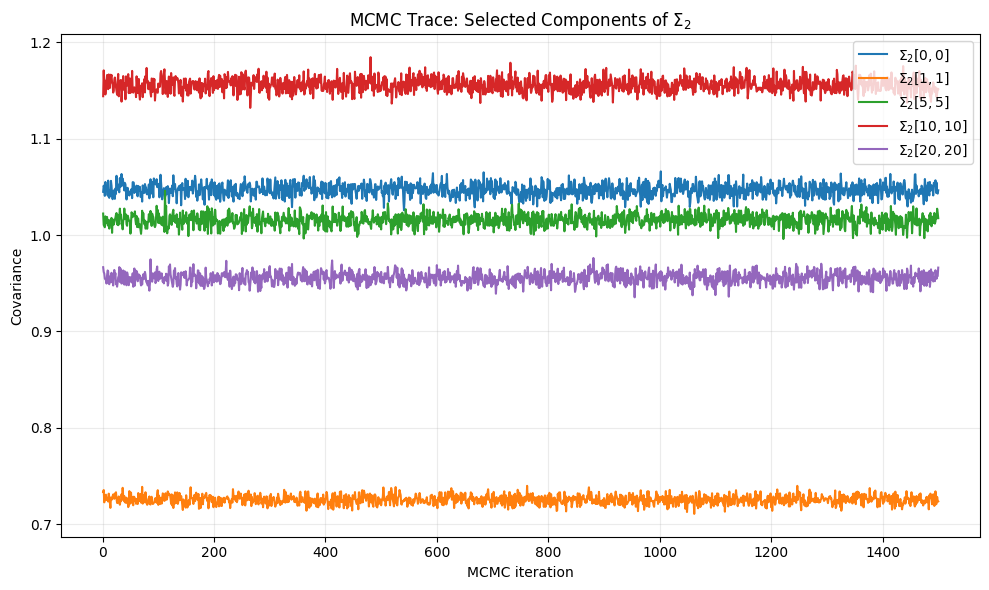

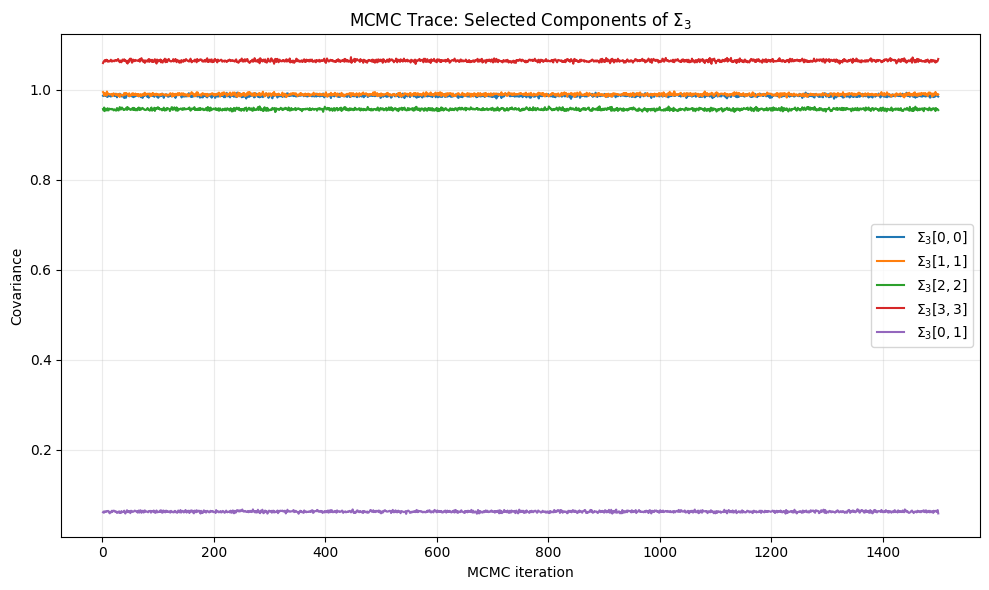

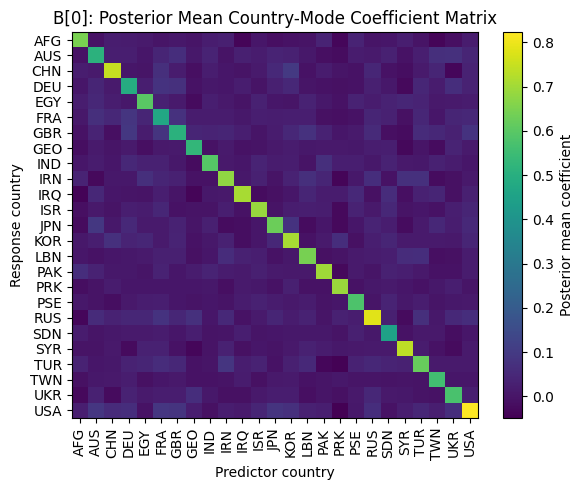

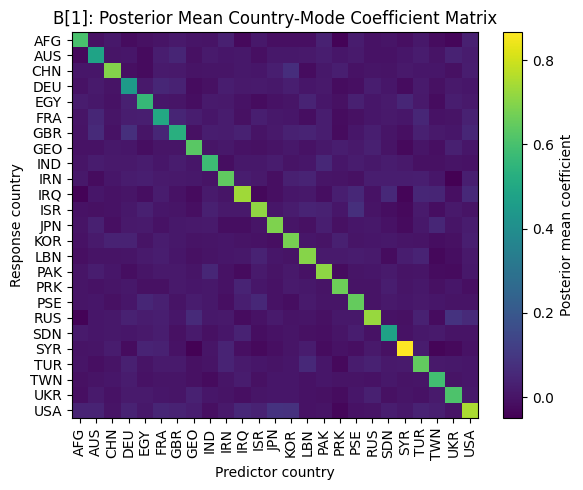

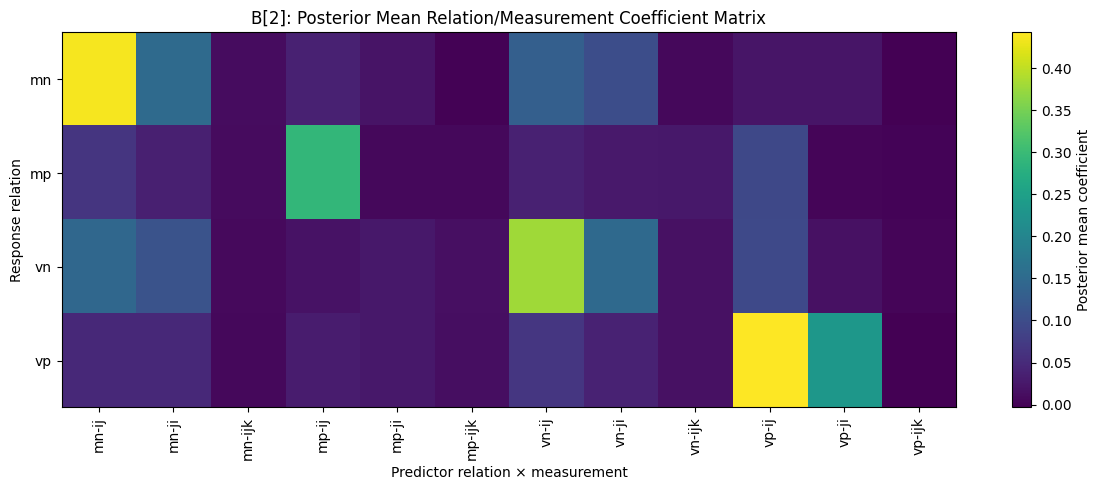

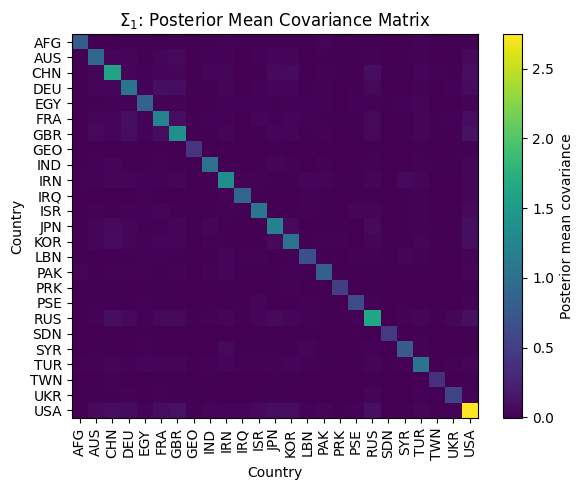

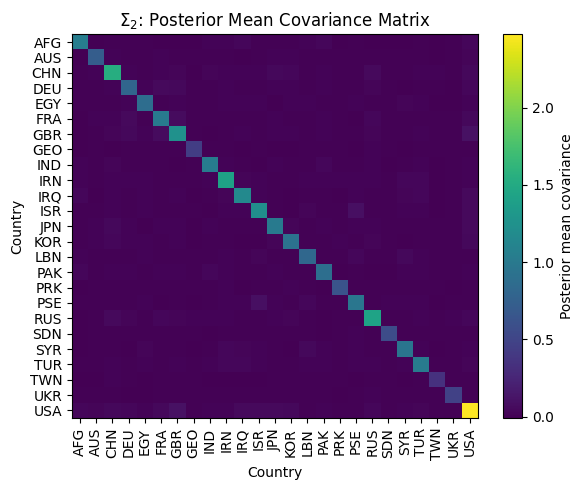

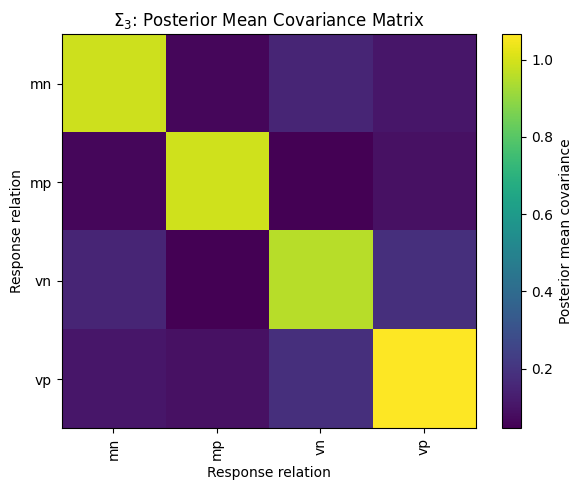

In [74]:

import json
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Load dimension names
# ============================================================

with open("data/dimnames_X_1w.json", "r") as f:
    dimnames_X_1w = json.load(f)

countries = dimnames_X_1w[0]

relations = dimnames_X_1w[2]

response_relations = [
    "mn",
    "mp",
    "vn",
    "vp"
]

predictor_names = [
    "mn-ij", "mn-ji", "mn-ijk",
    "mp-ij", "mp-ji", "mp-ijk",
    "vn-ij", "vn-ji", "vn-ijk",
    "vp-ij", "vp-ji", "vp-ijk"
]


# ============================================================
# MCMC traces: MSE and S2
# ============================================================

MSE = results["MSE"]
S2 = results["S2"]

iterations = np.arange(1, len(MSE) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    iterations,
    MSE,
    linewidth=1
)

plt.xlabel("MCMC iteration")
plt.ylabel("MSE")
plt.title("MCMC Trace: Mean Squared Error")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


plt.figure(figsize=(9, 5))

plt.plot(
    iterations,
    S2,
    linewidth=1
)

plt.xlabel("MCMC iteration")
plt.ylabel(r"$\tau^2$")
plt.title(r"MCMC Trace: Global Variance $\tau^2$")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# MCMC traces: selected components of B
# ============================================================

# ------------------------------------------------------------
# B[0]
# ------------------------------------------------------------

B0_trace = results["BPS"][0]

selected_B0 = [
    (0, 0),
    (0, 1),
    (1, 0),
    (1, 1),
    (5, 5)
]

plt.figure(figsize=(10, 6))

for i, j in selected_B0:

    plt.plot(
        np.arange(1, B0_trace.shape[2] + 1),
        B0_trace[i, j, :],
        label=f"B[0][{i},{j}]"
    )

plt.xlabel("MCMC iteration")
plt.ylabel("Coefficient")
plt.title("MCMC Trace: Selected Components of B[0]")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# B[1]
# ------------------------------------------------------------

B1_trace = results["BPS"][1]

selected_B1 = [
    (0, 0),
    (0, 1),
    (1, 0),
    (1, 1),
    (5, 5)
]

plt.figure(figsize=(10, 6))

for i, j in selected_B1:

    plt.plot(
        np.arange(1, B1_trace.shape[2] + 1),
        B1_trace[i, j, :],
        label=f"B[1][{i},{j}]"
    )

plt.xlabel("MCMC iteration")
plt.ylabel("Coefficient")
plt.title("MCMC Trace: Selected Components of B[1]")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# B[2]
# ------------------------------------------------------------

B2_trace = results["BPS"][2]

selected_B2 = [
    (0, 0),
    (0, 1),
    (0, 2),
    (1, 0),
    (1, 1),
    (2, 0)
]

plt.figure(figsize=(10, 6))

for i, j in selected_B2:

    plt.plot(
        np.arange(1, B2_trace.shape[2] + 1),
        B2_trace[i, j, :],
        label=f"B[2][{i},{j}]"
    )

plt.xlabel("MCMC iteration")
plt.ylabel("Coefficient")
plt.title("MCMC Trace: Selected Components of B[2]")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# MCMC traces: selected components of Sigma
# ============================================================

# ------------------------------------------------------------
# Sigma[0]
# ------------------------------------------------------------

S0_trace = results["SPS"][0]

selected_S0 = [
    (0, 0),
    (1, 1),
    (5, 5),
    (10, 10),
    (20, 20)
]

plt.figure(figsize=(10, 6))

for i, j in selected_S0:

    plt.plot(
        np.arange(1, S0_trace.shape[2] + 1),
        S0_trace[i, j, :],
        label=rf"$\Sigma_1[{i},{j}]$"
    )

plt.xlabel("MCMC iteration")
plt.ylabel("Covariance")
plt.title(r"MCMC Trace: Selected Components of $\Sigma_1$")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Sigma[1]
# ------------------------------------------------------------

S1_trace = results["SPS"][1]

selected_S1 = [
    (0, 0),
    (1, 1),
    (5, 5),
    (10, 10),
    (20, 20)
]

plt.figure(figsize=(10, 6))

for i, j in selected_S1:

    plt.plot(
        np.arange(1, S1_trace.shape[2] + 1),
        S1_trace[i, j, :],
        label=rf"$\Sigma_2[{i},{j}]$"
    )

plt.xlabel("MCMC iteration")
plt.ylabel("Covariance")
plt.title(r"MCMC Trace: Selected Components of $\Sigma_2$")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Sigma[2]
# ------------------------------------------------------------

S2_trace = results["SPS"][2]

selected_S2 = [
    (0, 0),
    (1, 1),
    (2, 2),
    (3, 3),
    (0, 1)
]

plt.figure(figsize=(10, 6))

for i, j in selected_S2:

    plt.plot(
        np.arange(1, S2_trace.shape[2] + 1),
        S2_trace[i, j, :],
        label=rf"$\Sigma_3[{i},{j}]$"
    )

plt.xlabel("MCMC iteration")
plt.ylabel("Covariance")
plt.title(r"MCMC Trace: Selected Components of $\Sigma_3$")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# Posterior mean of B
# ============================================================

# Compute posterior means after burn-in.
# Change burn_in according to your MCMC configuration.

burn_in = results["burn_in"]

B_posterior_mean = []

for k in range(len(results["BPS"])):

    B_mean = np.mean(
        results["BPS"][k][:, :, burn_in:],
        axis=2
    )

    B_posterior_mean.append(B_mean)


# ============================================================
# Posterior mean: B[0]
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    B_posterior_mean[0],
    aspect="auto"
)

plt.colorbar(
    label="Posterior mean coefficient"
)

plt.xticks(
    range(len(countries)),
    countries,
    rotation=90
)

plt.yticks(
    range(len(countries)),
    countries
)

plt.xlabel("Predictor country")
plt.ylabel("Response country")

plt.title(
    "B[0]: Posterior Mean Country-Mode Coefficient Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# Posterior mean: B[1]
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    B_posterior_mean[1],
    aspect="auto"
)

plt.colorbar(
    label="Posterior mean coefficient"
)

plt.xticks(
    range(len(countries)),
    countries,
    rotation=90
)

plt.yticks(
    range(len(countries)),
    countries
)

plt.xlabel("Predictor country")
plt.ylabel("Response country")

plt.title(
    "B[1]: Posterior Mean Country-Mode Coefficient Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# Posterior mean: B[2]
# ============================================================

plt.figure(figsize=(12, 5))

plt.imshow(
    B_posterior_mean[2],
    aspect="auto"
)

plt.colorbar(
    label="Posterior mean coefficient"
)

plt.xticks(
    range(12),
    predictor_names,
    rotation=90
)

plt.yticks(
    range(4),
    response_relations
)

plt.xlabel(
    "Predictor relation × measurement"
)

plt.ylabel(
    "Response relation"
)

plt.title(
    "B[2]: Posterior Mean Relation/Measurement Coefficient Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# Posterior mean of Sigma
# ============================================================

S_posterior_mean = []

for k in range(len(results["SPS"])):

    S_mean = np.mean(
        results["SPS"][k][:, :, burn_in:],
        axis=2
    )

    S_posterior_mean.append(S_mean)


# ============================================================
# Sigma[0] posterior mean
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    S_posterior_mean[0],
    aspect="auto"
)

plt.colorbar(
    label="Posterior mean covariance"
)

plt.xticks(
    range(len(countries)),
    countries,
    rotation=90
)

plt.yticks(
    range(len(countries)),
    countries
)

plt.xlabel("Country")
plt.ylabel("Country")

plt.title(
    r"$\Sigma_1$: Posterior Mean Covariance Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# Sigma[1] posterior mean
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    S_posterior_mean[1],
    aspect="auto"
)

plt.colorbar(
    label="Posterior mean covariance"
)

plt.xticks(
    range(len(countries)),
    countries,
    rotation=90
)

plt.yticks(
    range(len(countries)),
    countries
)

plt.xlabel("Country")
plt.ylabel("Country")

plt.title(
    r"$\Sigma_2$: Posterior Mean Covariance Matrix"
)

plt.tight_layout()
plt.show()


# ============================================================
# Sigma[2] posterior mean
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(
    S_posterior_mean[2],
    aspect="auto"
)

plt.colorbar(
    label="Posterior mean covariance"
)

plt.xticks(
    range(4),
    response_relations,
    rotation=90
)

plt.yticks(
    range(4),
    response_relations
)

plt.xlabel("Response relation")
plt.ylabel("Response relation")

plt.title(
    r"$\Sigma_3$: Posterior Mean Covariance Matrix"
)

plt.tight_layout()
plt.show()